# MEMC exercise 0 – Probability and statistics refresher

---

This notebook is **preparation before the course**. We go through only what we will keep using
over and over in the later exercises:

- random variable, expectation and variance
- the basic distributions (uniform, normal, exponential, Bernoulli, binomial, Poisson)
- the law of large numbers
- **Chebyshev's inequality**
- **the central limit theorem (CLT)**
- how to turn all of that into a confidence interval for a Monte Carlo estimate

The emphasis is on **practice**: for every concept you get a short explanation, code and a plot.
The standard libraries `random` and `math`, plus `matplotlib` for the plots, are all you need.

> Goal: after this notebook you should know why a Monte Carlo estimate converges, and how large
> an error it carries.

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def samples(sampler, n):
    '''n calls of the generator -> list of samples.'''
    return [sampler() for _ in range(n)]


def estimate(xs):
    '''Mean and its standard error s / sqrt(n) from a finished list of samples.'''
    n = len(xs)
    mean = sum(xs) / n
    var = sum((x - mean) ** 2 for x in xs) / (n - 1)  # sample variance
    return mean, math.sqrt(var / n)


def Phi(x):
    '''Distribution function of N(0, 1), via the error function erf.'''
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))

## 1. Random variable and generator

A **random variable** $X$ is a number whose value depends on chance. It is described by its
distribution:

| Type | Description | Example |
|------|-------------|---------|
| Discrete | values $x_k$ with probabilities $p_k$ | a die roll |
| Continuous | density $f(x)$, $P(a \le X \le b) = \int_a^b f(x)\,dx$ | waiting time for a tram |

The distribution function $F(x) = P(X \le x)$ exists for both types.

**For a computer** there is just one basic generator: `random.random()` returns a number from the
uniform distribution on $[0, 1)$. Everything else in the course we will **build** out of it.

> A computer generates *pseudorandom* numbers – a deterministic algorithm that pretends to be
> random. With the same `seed` you get the same sequence, which is handy for debugging.

[0.1344, 0.8474, 0.7638, 0.2551, 0.4954]


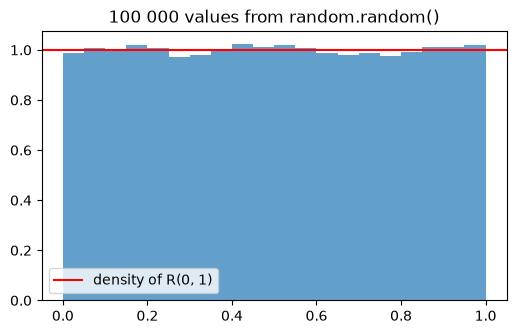

In [2]:
print([round(random.random(), 4) for _ in range(5)])

xs = samples(random.random, 100_000)
plt.figure(figsize=(6, 3.5))
plt.hist(xs, bins=20, range=(0, 1), density=True, alpha=0.7)
plt.axhline(1.0, color="red", label="density of R(0, 1)")
plt.title("100 000 values from random.random()")
plt.legend()
plt.show()

## 2. Expectation and variance

| | Discrete | Continuous |
|---|-----------|---------|
| Expectation $E X$ | $\sum_k x_k p_k$ | $\int x f(x)\,dx$ |
| Variance $D X$ | $\sum_k (x_k - E X)^2 p_k$ | $\int (x - E X)^2 f(x)\,dx$ |

The standard deviation is $\sigma = \sqrt{D X}$. The rules we will be using:

- $E(aX + b) = a\,E X + b$ and $E(X + Y) = E X + E Y$ (always)
- $D(aX + b) = a^2 D X$
- $D(X + Y) = D X + D Y$ (**only for independent** $X, Y$)
- $D X = E X^2 - (E X)^2$

### Monte Carlo in one sentence

Don't know the expectation? Simulate $N$ independent copies $X_1, \dots, X_N$ and take the average

$$\bar X_N = \frac{1}{N}\sum_{i=1}^N X_i \approx E X.$$

The variance of the average is $D\bar X_N = \sigma^2 / N$, so the **standard error** is
$\sigma/\sqrt{N}$.

### Example: a die roll

In [3]:
values = [1, 2, 3, 4, 5, 6]
p = [1 / 6] * 6

EX = sum(x * q for x, q in zip(values, p))
VarX = sum((x - EX) ** 2 * q for x, q in zip(values, p))
print(f"exact:     E X = {EX:.4f},  Var X = {VarX:.4f}  (= 35/12 = {35/12:.4f})")

xs = samples(lambda: random.randint(1, 6), 100_000)
m, se = estimate(xs)
print(f"simulated: E X = {m:.4f} +- {se:.4f}")
print(f"deviation from the exact value: {m - EX:+.4f}  (that is {abs(m - EX) / se:.1f} standard errors)")

exact:     E X = 3.5000,  Var X = 2.9167  (= 35/12 = 2.9167)
simulated: E X = 3.4960 +- 0.0054
deviation from the exact value: -0.0040  (that is 0.7 standard errors)


The deviation is typically within **two** standard errors. Why exactly that many is what the CLT
explains below.

## 3. The basic distributions

| Distribution | Parameters | $E X$ | $D X$ | Used for |
|--------------|------------|-------|-------|----------|
| Bernoulli | $p$ | $p$ | $p(1-p)$ | yes/no (did an event happen?) |
| Binomial | $n, p$ | $np$ | $np(1-p)$ | number of successes out of $n$ trials |
| Poisson | $\lambda$ | $\lambda$ | $\lambda$ | number of events in a time span |
| Uniform | $a, b$ | $(a+b)/2$ | $(b-a)^2/12$ | the basis of everything |
| Exponential | $\lambda$ | $1/\lambda$ | $1/\lambda^2$ | time until an event |
| Normal | $\mu, \sigma^2$ | $\mu$ | $\sigma^2$ | sums and averages (CLT) |

Below we check the table by simulation. The generators are taken from the standard library; we
will "build them ourselves" only in the later exercises (discrete: exercise 3, continuous:
exercise 4).

In [4]:
def bernoulli(p):
    return 1 if random.random() < p else 0


def binomial(n, p):
    return sum(bernoulli(p) for _ in range(n))


sources = [
    # name, generator, exact E, exact Var
    ("Bernoulli(0.3)",    lambda: bernoulli(0.3),           0.3, 0.3 * 0.7),
    ("Binomial(10, 0.3)", lambda: binomial(10, 0.3),        3.0, 10 * 0.3 * 0.7),
    ("Uniform(2, 5)",     lambda: random.uniform(2, 5),     3.5, 9 / 12),
    ("Exponential(2)",    lambda: random.expovariate(2.0),  0.5, 0.25),
    ("Normal(1, 2)",      lambda: random.gauss(1.0, 2.0),   1.0, 4.0),
]

print(f"{'distribution':20s} {'E (sim)':>10s} {'E (exact)':>11s} {'Var (sim)':>10s} {'Var (exact)':>13s}")
for name, gen, E, V in sources:
    xs = samples(gen, 100_000)
    m = sum(xs) / len(xs)
    v = sum((x - m) ** 2 for x in xs) / (len(xs) - 1)
    print(f"{name:20s} {m:10.4f} {E:11.4f} {v:10.4f} {V:13.4f}")

distribution            E (sim)   E (exact)  Var (sim)   Var (exact)
Bernoulli(0.3)           0.3016      0.3000     0.2106        0.2100
Binomial(10, 0.3)        3.0006      3.0000     2.0929        2.1000
Uniform(2, 5)            3.4972      3.5000     0.7515        0.7500
Exponential(2)           0.5001      0.5000     0.2488        0.2500
Normal(1, 2)             1.0008      1.0000     3.9949        4.0000


### The Poisson distribution from its definition

The Poisson distribution has $P(X = k) = \dfrac{\lambda^k e^{-\lambda}}{k!}$. The standard library
does not provide it, but we can get the expectation and the variance **straight from the
definition** by summing (we truncate the sum, the tail is negligible):

In [5]:
lam = 4.0
pmf = [lam ** k * math.exp(-lam) / math.factorial(k) for k in range(60)]

EX = sum(k * q for k, q in enumerate(pmf))
VarX = sum((k - EX) ** 2 * q for k, q in enumerate(pmf))
print(f"sum p_k = {sum(pmf):.6f},  E X = {EX:.6f},  Var X = {VarX:.6f}   (both should be lambda = {lam})")

sum p_k = 1.000000,  E X = 4.000000,  Var X = 4.000000   (both should be lambda = 4.0)


### What the densities and mass functions look like

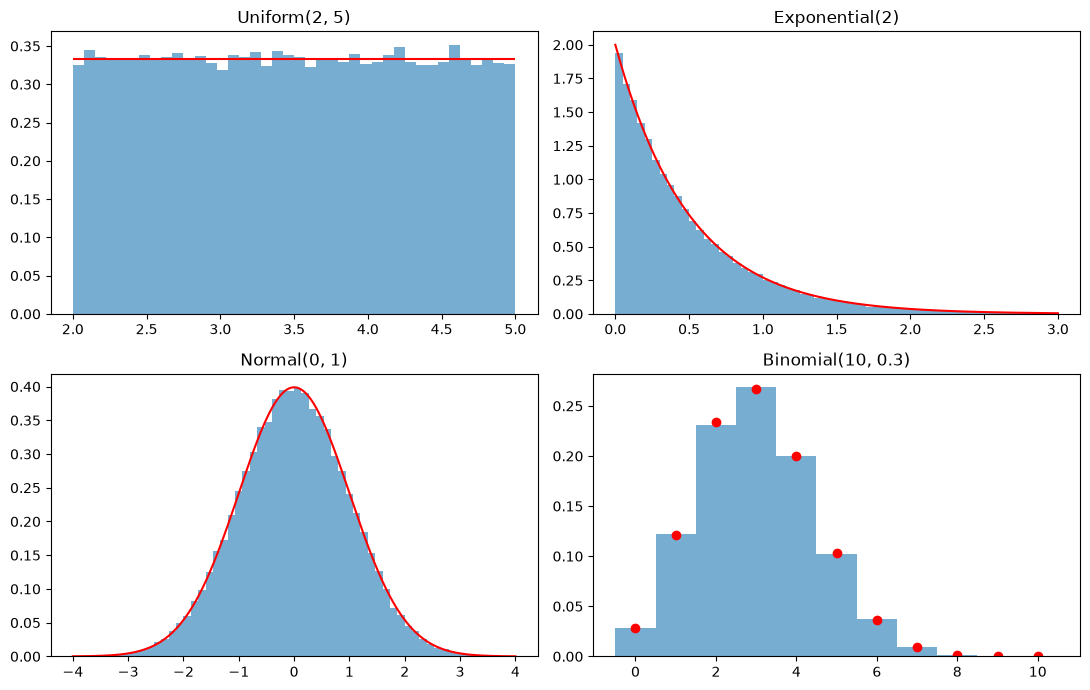

In [6]:
n = 100_000
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

# uniform
xs = samples(lambda: random.uniform(2, 5), n)
ax = axes[0][0]
ax.hist(xs, bins=40, density=True, alpha=0.6)
ax.hlines(1 / 3, 2, 5, color="red")
ax.set_title("Uniform(2, 5)")

# exponential
xs = samples(lambda: random.expovariate(2.0), n)
ax = axes[0][1]
ax.hist(xs, bins=60, range=(0, 3), density=True, alpha=0.6)
grid = [i / 100 for i in range(301)]
ax.plot(grid, [2 * math.exp(-2 * x) for x in grid], "r")
ax.set_title("Exponential(2)")

# normal
xs = samples(lambda: random.gauss(0, 1), n)
ax = axes[1][0]
ax.hist(xs, bins=60, range=(-4, 4), density=True, alpha=0.6)
grid = [i / 50 - 4 for i in range(401)]
ax.plot(grid, [math.exp(-x * x / 2) / math.sqrt(2 * math.pi) for x in grid], "r")
ax.set_title("Normal(0, 1)")

# binomial
xs = samples(lambda: binomial(10, 0.3), n)
ax = axes[1][1]
ax.hist(xs, bins=[k - 0.5 for k in range(12)], density=True, alpha=0.6)
ax.plot(range(11), [math.comb(10, k) * 0.3 ** k * 0.7 ** (10 - k) for k in range(11)], "ro")
ax.set_title("Binomial(10, 0.3)")

plt.tight_layout()
plt.show()

Blue is the histogram from the simulation, red the exact density (resp. the probability mass
function). They agree, so the generators work.

## 4. The law of large numbers

> **Law of large numbers (LLN):** for independent $X_i$ with the same expectation $\mu$,
> $\bar X_N \to \mu$ as $N \to \infty$.

This is the reason Monte Carlo works *at all*. Let us look at the running average of die rolls in
five independent runs:

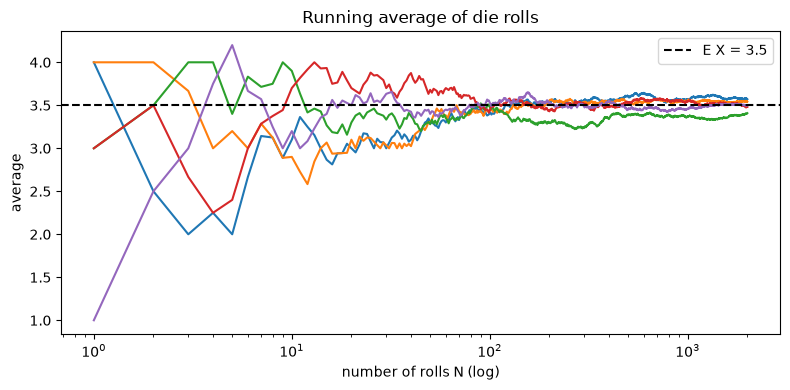

In [7]:
plt.figure(figsize=(8, 4))
for _ in range(5):
    s = 0
    running = []
    for i in range(1, 2001):
        s += random.randint(1, 6)
        running.append(s / i)
    plt.plot(range(1, 2001), running)

plt.axhline(3.5, color="black", linestyle="--", label="E X = 3.5")
plt.xscale("log")
plt.xlabel("number of rolls N (log)")
plt.ylabel("average")
plt.title("Running average of die rolls")
plt.legend()
plt.tight_layout()
plt.show()

All five curves settle at $3.5$. But the LLN only says **that** the average converges, not **how
fast** nor **how large an error** we have after $N$ steps. For that we need two tools: Chebyshev's
inequality and the CLT.

## 5. Chebyshev's inequality

For **any** distribution with finite variance and every $k > 0$,

$$P\big(|X - \mu| \ge k\sigma\big) \le \frac{1}{k^2}.$$

For the average $\bar X_N$ (whose variance is $\sigma^2/N$) and a tolerance $\delta$:

$$P\big(|\bar X_N - \mu| \ge \delta\big) \le \frac{\sigma^2}{N\delta^2}.$$

**Strength:** it always holds, we assume nothing about the shape of the distribution.
**Weakness:** it is very **conservative** (the upper bound is often grossly inflated).

Let us compare the actual probabilities against the bound $1/k^2$:

In [8]:
def chebyshev_table(name, gen, mu, sigma, n=200_000, normal=False):
    xs = samples(gen, n)
    print(name)
    print(f"  {'k':>4s} {'actual':>12s} {'Chebyshev <=':>14s}" + (f" {'normal (exact)':>16s}" if normal else ""))
    for k in (1.5, 2, 3, 4):
        emp = sum(abs(x - mu) >= k * sigma for x in xs) / n
        row = f"  {k:4.1f} {emp:12.4f} {1 / k ** 2:14.4f}"
        if normal:
            row += f" {2 * (1 - Phi(k)):16.4f}"
        print(row)
    print()


chebyshev_table("Uniform(0, 1)", random.random, 0.5, math.sqrt(1 / 12))
chebyshev_table("Exponential(1)", lambda: random.expovariate(1.0), 1.0, 1.0)
chebyshev_table("Normal(0, 1)", lambda: random.gauss(0, 1), 0.0, 1.0, normal=True)

Uniform(0, 1)
     k       actual   Chebyshev <=
   1.5       0.1345         0.4444
   2.0       0.0000         0.2500
   3.0       0.0000         0.1111
   4.0       0.0000         0.0625

Exponential(1)
     k       actual   Chebyshev <=
   1.5       0.0812         0.4444
   2.0       0.0490         0.2500
   3.0       0.0178         0.1111
   4.0       0.0067         0.0625

Normal(0, 1)
     k       actual   Chebyshev <=   normal (exact)
   1.5       0.1330         0.4444           0.1336
   2.0       0.0455         0.2500           0.0455
   3.0       0.0028         0.1111           0.0027
   4.0       0.0001         0.0625           0.0001



The bounds always hold, but for the normal distribution the actual probability at $k = 3$ is about
$0.003$, while Chebyshev only promises $\le 0.111$. That is the price of generality.

> Chebyshev's inequality requires a **finite variance**. For the Cauchy distribution the variance
> does not exist (and neither does the expectation), so neither the inequality nor the LLN holds.
> We will see that in exercise 4.

## 6. The central limit theorem (CLT)

> **CLT:** let $X_i$ be independent with the same distribution, expectation $\mu$ and variance
> $\sigma^2 \in (0, \infty)$. Then the standardized average
> $$Z_N = \frac{\bar X_N - \mu}{\sigma/\sqrt{N}}$$
> converges in distribution to $N(0, 1)$.

In other words: **whatever the original distribution is**, the average of many copies looks like a
bell. Let us have a look. The rows are two very different distributions (symmetric and strongly
skewed), the columns are increasing $N$:

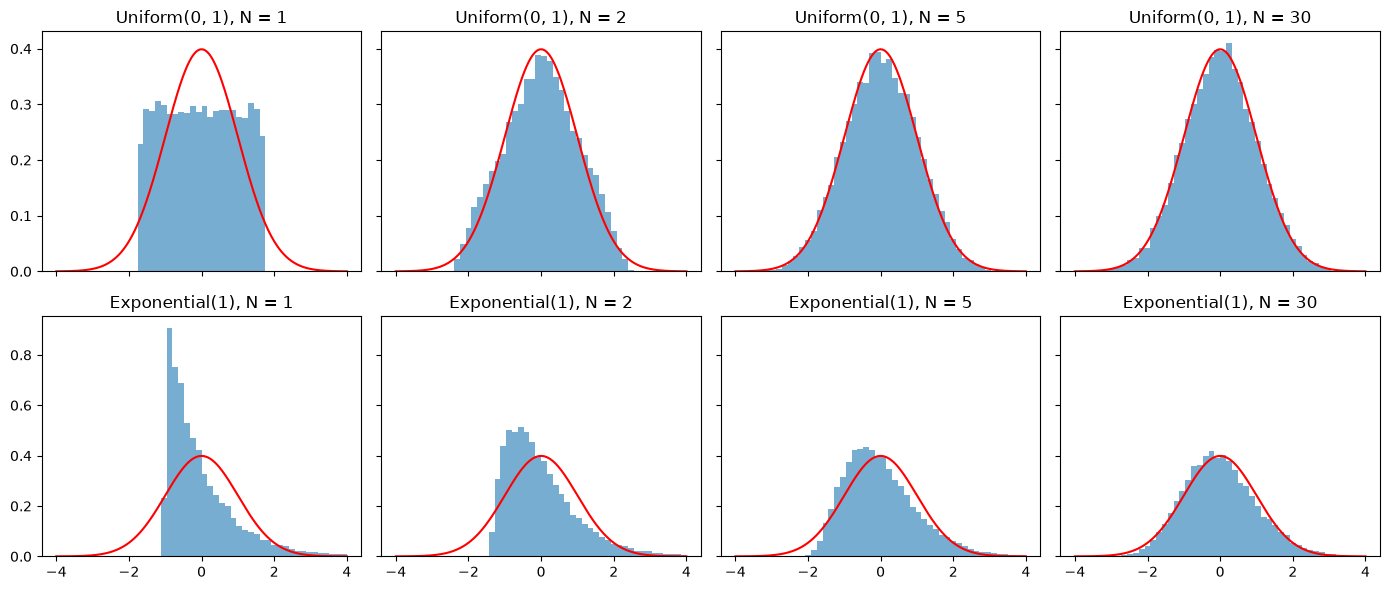

In [9]:
def standardized_averages(gen, mu, sigma, N, runs=20_000):
    out = []
    for _ in range(runs):
        s = 0.0
        for _ in range(N):
            s += gen()
        out.append((s / N - mu) / (sigma / math.sqrt(N)))
    return out


clt_sources = [
    ("Uniform(0, 1)", random.random, 0.5, math.sqrt(1 / 12)),
    ("Exponential(1)", lambda: random.expovariate(1.0), 1.0, 1.0),
]
Ns = (1, 2, 5, 30)
grid = [i / 50 - 4 for i in range(401)]
pdf = [math.exp(-x * x / 2) / math.sqrt(2 * math.pi) for x in grid]

fig, axes = plt.subplots(len(clt_sources), len(Ns), figsize=(14, 6), sharex=True, sharey="row")
for r, (name, gen, mu, sigma) in enumerate(clt_sources):
    for c, N in enumerate(Ns):
        z = standardized_averages(gen, mu, sigma, N)
        ax = axes[r][c]
        ax.hist(z, bins=50, range=(-4, 4), density=True, alpha=0.6)
        ax.plot(grid, pdf, "r")
        ax.set_title(f"{name}, N = {N}")
plt.tight_layout()
plt.show()

Red is the density of $N(0, 1)$. For the uniform distribution $N = 5$ is enough; for the skewed
exponential one you need more: at $N = 30$ the bell already fits quite well, but the skew is still
visible. **The less symmetric the original distribution, the larger the $N$ the CLT needs.**

### Why "two sigmas" is enough in Monte Carlo

The CLT implies that with probability $\approx 95\,\%$ we have
$|\bar X_N - \mu| \le 1.96\,\sigma/\sqrt{N}$. In general $\delta = k_\alpha\,\sigma/\sqrt{N}$ and
the confidence level is $1 - \alpha$:

| Method | $k_\alpha$ for 95 % | Holds |
|--------|---------------------|-------|
| CLT (normal) | $\approx 1.96 \approx 2$ | approximately, for large $N$ |
| Chebyshev | $1/\sqrt{\alpha} \approx 4.47$ | always |

## 7. A confidence interval in practice (Bernoulli)

A typical Monte Carlo task: we estimate a probability $p$ (e.g. π, or the probability of ruin).
Each trial is Bernoulli: $X_i = 1$ with probability $p$. Then $\hat p = \bar X_N$ and
$\sigma^2 = p(1-p) \le 1/4$.

How many trials do we need to pin $p$ down to an accuracy of $\delta = 0.01$ at 95 %? For the worst
case $\sigma = 1/2$:

- CLT: $N \ge (1.96 \cdot 0.5 / \delta)^2 \approx 1/\delta^2$
- Chebyshev: $N \ge 1 / (4\alpha\delta^2) = 5/\delta^2$

In [10]:
delta, alpha = 0.01, 0.05

N_clt = (1.96 * 0.5 / delta) ** 2
N_cheb = 1 / (4 * alpha * delta ** 2)
print(f"CLT:       N >= {N_clt:,.0f}".replace(",", " "))
print(f"Chebyshev: N >= {N_cheb:,.0f}".replace(",", " ") + f"  (that is {N_cheb / N_clt:.1f}x more)")

CLT:       N >= 9 604
Chebyshev: N >= 50 000  (that is 5.2x more)


Chebyshev is safe, but roughly **5x more expensive**. Does the CLT interval really work the way it
promises, though? Let us try: we repeat the "estimate $p$" experiment 2000 times and count in how
many cases the true $p$ fell inside the interval.

In [11]:
def coverage(p, N, runs=2000, alpha=0.05):
    z = 1.96                        # CLT
    c = 1 / math.sqrt(alpha)        # Chebyshev
    ok_clt = ok_cheb = ok_cheb_worst = 0
    for _ in range(runs):
        p_hat = sum(random.random() < p for _ in range(N)) / N
        se = math.sqrt(p_hat * (1 - p_hat) / N)            # estimate of sigma/sqrt(N)
        err = abs(p_hat - p)
        ok_clt += err <= z * se
        ok_cheb += err <= c * se
        ok_cheb_worst += err <= c * 0.5 / math.sqrt(N)     # sigma <= 1/2, no estimate at all
    print(f"p = {p}, N = {N}: coverage CLT {ok_clt / runs:.3f}, "
          f"Chebyshev (estimated sigma) {ok_cheb / runs:.3f}, Chebyshev (sigma = 1/2) {ok_cheb_worst / runs:.3f}")


coverage(0.3, 400)
coverage(0.01, 100)

p = 0.3, N = 400: coverage CLT 0.969, Chebyshev (estimated sigma) 1.000, Chebyshev (sigma = 1/2) 1.000
p = 0.01, N = 100: coverage CLT 0.637, Chebyshev (estimated sigma) 0.638, Chebyshev (sigma = 1/2) 1.000


What follows from this:

- For $p = 0.3$ and $N = 400$ the CLT interval delivers its 95 % (the measured coverage fluctuates
  around 95–97 %, it is a random experiment).
- For **small $p$** (and few trials) the CLT fails: in roughly a third of the runs we get
  $\hat p = 0$, hence $\hat\sigma = 0$ and an interval of zero width, which does not capture the
  true value. A probability of ruin tends to be exactly that small, so we will watch out for this
  in the insurance exercise.
- Chebyshev with the worst-case $\sigma = 1/2$ always covers, at the price of a wide interval.

## 8. An alternative: NumPy

Everything above could be written with the standard library alone. With NumPy it is shorter and
faster (a whole array of samples at once). NumPy is installed automatically together with
matplotlib; SciPy will be an optional dependency (`uv sync --extra alt`) and shows up only in the
later exercises.

In [12]:
try:
    import numpy as np

    rng = np.random.default_rng(1)
    xs = rng.integers(1, 7, size=100_000)                 # a die, vectorized
    print(f"NumPy: E X = {xs.mean():.4f} +- {xs.std(ddof=1) / math.sqrt(xs.size):.4f}")

    # standardized averages of the exponential distribution, N = 30, no loops
    z = (rng.exponential(1.0, size=(20_000, 30)).mean(axis=1) - 1.0) / (1.0 / math.sqrt(30))
    print(f"NumPy: Z_30 has mean {z.mean():.3f} and variance {z.var():.3f}  (we expect 0 and 1)")
except ModuleNotFoundError:
    print("NumPy is not installed, run:  uv sync")

NumPy: E X = 3.4974 +- 0.0054
NumPy: Z_30 has mean -0.016 and variance 1.001  (we expect 0 and 1)


## Summary

| Concept | What to remember |
|---------|------------------|
| $E X$, $D X$ | the average and the variance; $D$ adds up only for independent variables |
| Monte Carlo estimate | $\bar X_N \approx E X$, standard error $\sigma/\sqrt{N}$ |
| Law of large numbers | the average converges to $\mu$ |
| Chebyshev | $P(\lvert\bar X - \mu\rvert \ge \delta) \le \sigma^2/(N\delta^2)$; always holds, but crude ($k \approx 4.47$ for 95 %) |
| CLT | $\bar X_N \approx N(\mu, \sigma/\sqrt N)$; sharper ($k \approx 1.96$), but only for large $N$ |
| Bernoulli | $\sigma^2 = p(1-p) \le 1/4$; for small $p$ be careful with the CLT |

### Try it yourself

1. Change `Ns` in the CLT plot to `(1, 10, 100)` and the source to a die (`random.randint(1, 6)`,
   $\mu = 3.5$, $\sigma = \sqrt{35/12}$). When does it start to look like a bell?
2. Work out how many trials you need for $\delta = 0.001$ at a confidence level of 99 %
   ($\alpha = 0.01$, CLT: $k \approx 2.576$). How does $N$ change when you want an estimate ten
   times as accurate?
3. Add $k = 1$ and $k = 1.2$ to the Chebyshev table. What does the inequality say for $k = 1$, and
   why is that piece of information useless?